# Light-powered microrobot controller: device and electrical validation

**OpenTCAD • Apache-2.0 • functional reimplementation project**

We first connect conceptual semiconductor drift–diffusion characterization to a
reduced electrical/electrochemical/bending system. We then digitize the published
PV curves and characterize a new PV-powered SKY130 clock with a real divider-cell
load. These two experiments have separate provenance: the terminal fit does not
calibrate the conceptual TCAD structure. Actuator drivers and mechanics remain
reduced models; controller layout has not yet been implemented.

Reynolds et al. (2022), [paper](https://doi.org/10.1126/scirobotics.abq2296), is the initial
inspiration. Miskin et al. (2020), [paper](https://doi.org/10.1038/s41586-020-2626-9), supplies
supporting actuator physics. Lassiter et al. (2025), [preprint](https://arxiv.org/abs/2503.23085),
is future work. See `references.md` for evidence and `data/README.md` for extraction.
The user supplied the 2022 supplement on 2026-10-27 after publisher access failed.
Figure S1 confirms the shared lower rail and actuator midpoint/switch connections.
The paper states that all data are in the main text or supplementary materials;
the broken Zenodo link is optional and does not block these figure comparisons.
Transistor sizing and a uniquely calibrated PV process are not disclosed.


## 1. Reproduce and inspect the environment

Run from an environment matching `requirements-lock.txt` (tested Python 3.14.2).
Install the root repository editable with `pip install --no-deps -e .` after the lock.
No downloads happen during execution. The notebook reruns the experiment and saves
JSON, CSV, figures, generated decks and logs. Optional ngspice/SKY130 execution is
selected only when both are installed. Set `PDK_ROOT` to the parent of `sky130A`.
The root package does not depend on this application or ngspice.


In [1]:
from pathlib import Path
import json
import os
import shutil
import subprocess
import sys
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").is_file() and (p / "opentcad").is_dir())
OUTPUT = ROOT / "examples/microrobot/results"
pdk = Path(os.environ.get("PDK_ROOT", "/usr/local/share/pdk")) / "sky130A"
RUN_SPICE = bool(shutil.which("ngspice") and (pdk / "libs.tech/ngspice/sky130.lib.spice").is_file())
print("Python:", sys.version.split()[0], "| ngspice/SKY130 enabled:", RUN_SPICE)
OUTPUT.mkdir(parents=True, exist_ok=True)
command = [sys.executable, "-m", "examples.microrobot.run", "--output", str(OUTPUT)]
if RUN_SPICE:
    command.append("--spice")
with (OUTPUT / "notebook_run.log").open("w") as log:
    subprocess.run(command, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT, check=True)
def read(name):
    return json.loads((OUTPUT / name).read_text())
print("Experiments completed; numerical acceptance checks passed.")
print(json.dumps(read("environment.json"), indent=2))

Python: 3.14.2 | ngspice/SKY130 enabled: True


Experiments completed; numerical acceptance checks passed.
{
  "python": "3.14.2",
  "platform": "macOS-15.7.2-arm64-arm-64bit-Mach-O",
  "packages": {
    "numpy": "2.4.4",
    "scipy": "1.17.1",
    "devsim": "2.10.0",
    "gmsh": "4.15.2",
    "pyvista": "0.47.3",
    "matplotlib": "3.10.8",
    "pydantic": "2.13.3",
    "PyYAML": "6.0.3",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.4.0",
    "ViennaLS": "5.9.0"
  }
}


## 2. Device physics and dimensional accounting

`BeerLambert` prescribes $G(d)=Y(1-R)\Phi\alpha e^{-\alpha d}$ in pairs/cm³/s,
with $\Phi=P_{\rm inc}/(hc/\lambda)$ converted from m⁻² to cm⁻². Its depth integral
is checked against $Y(1-R)\Phi(1-e^{-\alpha t})$. The DD continuity residuals use
opposite electron/hole sources, $-qR+qG$ and $+qR-qG$, to conserve charge.

This conceptual silicon cross-section is 1 µm wide and 3 µm thick, with an abrupt
0.3 µm n-type layer. Doping, alpha=3000 cm⁻¹, reflection=0.3 and lifetime are explicit
choices, not a foundry structure or a fit. Top/back contacts are ideal transparent
ohmic contacts; sides have zero normal flux. Surface recombination and shading are
absent. The material database is not calibrated for temperature-dependent PVs.

DEVSIM integrates current in **A/cm of out-of-plane depth**. For 1 µm depth we
multiply by $10^{-4}$ cm to obtain A for a 1 µm² footprint. Scaling a table by physical
cell area assumes translational invariance and ignores finite-device edge losses.
Long bulk lifetime alone does not ensure full collection at absorbing ohmic contacts.


dark            : nodes=2515; Isc=-0.000000 nA/um²; Voc=0.0000 V; lifetime=1e-05 s
light           : nodes=2515; Isc=0.135497 nA/um²; Voc=0.4606 V; lifetime=1e-05 s
medium_mesh     : nodes= 725; Isc=0.135993 nA/um²; Voc=0.4607 V; lifetime=1e-05 s
coarse_mesh     : nodes= 233; Isc=0.137081 nA/um²; Voc=0.4610 V; lifetime=1e-05 s
half_light      : nodes=2515; Isc=0.067748 nA/um²; Voc=0.4437 V; lifetime=1e-05 s
short_lifetime  : nodes=2515; Isc=0.134380 nA/um²; Voc=0.4544 V; lifetime=1e-08 s
Absorbed-photon current upper bound: 2.2112883792006507e-10 A/um²


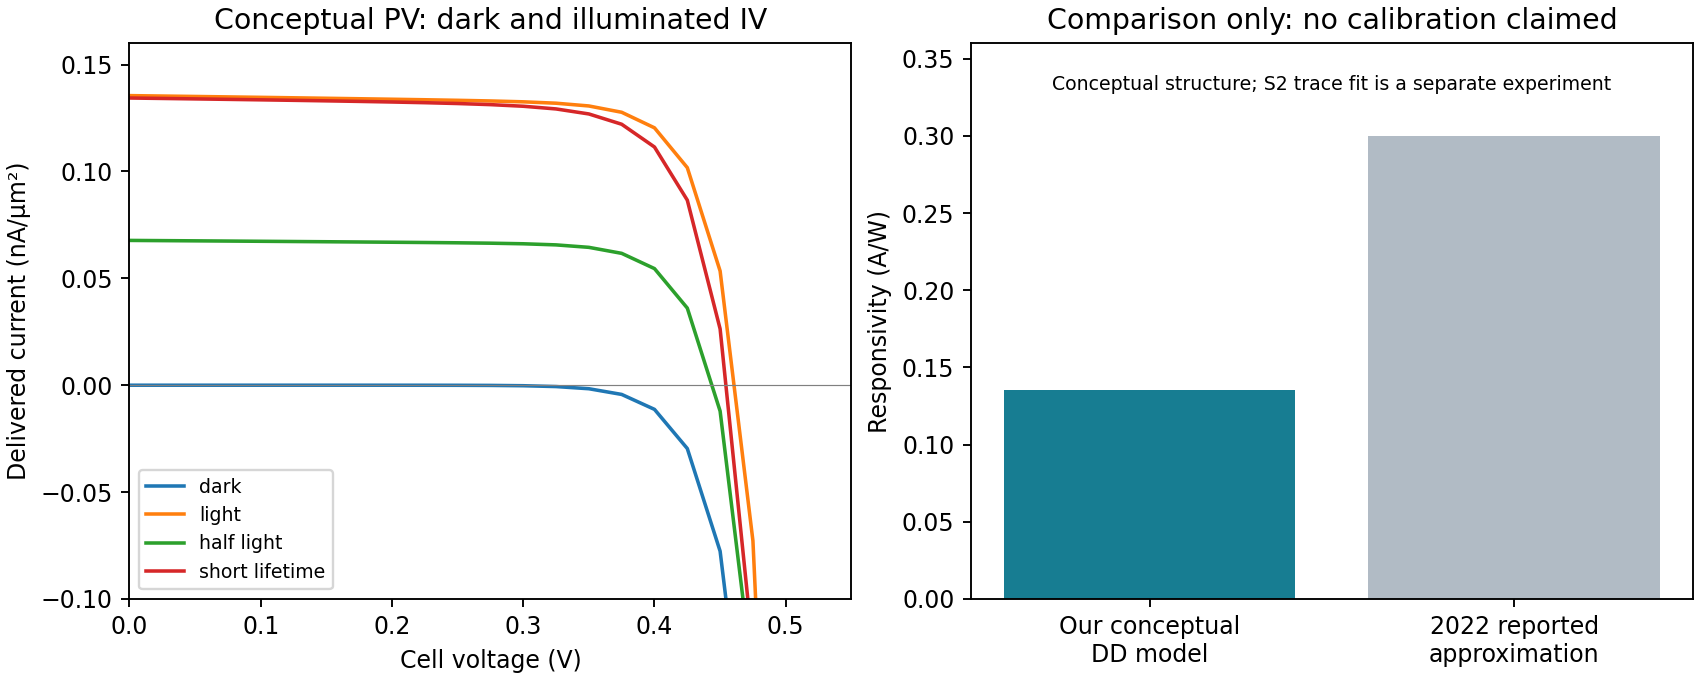

In [2]:
pv = read("pv.json")
for key in ("dark", "light", "medium_mesh", "coarse_mesh", "half_light", "short_lifetime"):
    r = pv[key]
    print(f"{key:16s}: nodes={r['nodes']:4d}; Isc={r['isc_A_per_um2']*1e9:.6f} nA/um²; "
          f"Voc={r['voc_V']:.4f} V; lifetime={r['lifetime_s']:.0e} s")
print("Absorbed-photon current upper bound:", pv["light"]["absorbed_photon_limit_A_per_um2"], "A/um²")
display(Image(filename=str(OUTPUT / "pv.png")))

The reported paper responsivity is an approximate comparison anchor for this
conceptual DD structure. Section 7 separately fits the supplement's digitized
dark/illuminated terminal curves. Neither numerical convergence nor a terminal
fit establishes a unique experimentally validated TCAD geometry. Lifetimes,
reflection, absorption and contact/surface losses remain non-identifiable from
the available aggregate measurements. All chosen parameters remain explicit.


## 3. Supply and electrode topology

The paper allocates a small PV pair to the IC and a large pair to actuator power,
and uses exposed Pt solution-return electrodes. Figure S1B, now inspected, confirms
the shared lower rail and two-cell actuator midpoint/switch topology.
The first conceptual experiment uses four logic cells; the published-curve
experiment in Section 7 uses three cells because the fitted cell voltage is higher.
These are supply adaptations for SKY130, not an exact reconstruction. Four fitted
cells would exceed the controller voltage range. Stronger light also requires an
overvoltage solution for the three-cell stack; this is unresolved design work.

The numerical coordinate zero is the Pt return **metal**; physical CMOS VSS is the
bottom actuator rail. Electrolyte potential floats according to its resistive return
and the finite Pt interface. No Ag/AgCl offset is inferred. In hardware, driver gate
level shifting, body/well ties and startup must be verified with the chosen PDK.

`logic_V` in reports/plots is the supply span VDDL−VSS. Actuator rails and
electrolyte voltages use the Pt return metal as zero. Thus VDDL versus Pt
is `logic_V - negative_magnitude_V`; these voltage references are distinct.


In [3]:
from dataclasses import asdict
from examples.microrobot.system import Parameters
print(json.dumps(asdict(Parameters()), indent=2))

{
  "logic_series_cells": 4,
  "logic_cell_area_um2": 150,
  "actuator_cell_area_um2": 500,
  "logic_storage_F": 5e-11,
  "actuator_storage_each_F": 2e-10,
  "bias_current_A": 5e-09,
  "logic_leakage_A": 2e-10,
  "effective_switched_F": 5e-14,
  "clock_Hz_at_1v6": 32768,
  "divider": 16384,
  "brownout_on_V": 1.6,
  "brownout_off_V": 1.45,
  "driver_ohm": 100000000.0,
  "solution_each_ohm": 10000000.0,
  "solution_return_ohm": 1000000.0,
  "actuator_area_um2": 200,
  "return_area_um2": 2000,
  "double_layer_F_m2": 0.2,
  "adsorption_C_m2": 1.3,
  "adsorption_midpoint_V": 0.0,
  "adsorption_width_V": 0.08,
  "adsorption_tau_s": 0.02,
  "faradaic_each_ohm": 10000000000.0,
  "mechanical_tau_s": 0.05,
  "curvature_span_m_inv": 100000.0,
  "hinge_length_um": 10
}


## 4. Clock, two phases, electrochemistry and bending

In this initial conceptual experiment, the clock is a supply-dependent phase accumulator divided to a few hertz,
with hysteretic brownout and reset. Two ideal switches with finite driver resistance
produce 90°-separated outputs. Analog bias and switched-logic loads are assumptions.
They are not derived from the separate SPICE candidate. Storage capacitor area is
unresolved and cannot be assumed to fit the paper's controller footprint.

Each SEA and the Pt return obey
$ I=C_{dl}\dot\eta+Q_{max}\dot\theta+\eta/R_F $.
Adsorption relaxes toward a logistic coverage curve; the electrolyte network satisfies
KCL. Mechanical curvature has a separate relaxation time and depends on coverage;
hinge angle is curvature times hinge length. Adsorption offset, kinetics, double-layer
capacitance, leakage and geometry are uncalibrated. The supporting paper's mechanical
time belongs to another geometry and is only a scale for exploration.

The shaded interval removes illumination. Observe separate supply collapse, clock
brownout, interface discharge and mechanical relaxation. No walking speed follows
from these bending traces.


{
  "startup_enable_s": 0.056,
  "enable_transitions": 2,
  "mean_gait_Hz": 2.2413597403595835,
  "measured_phase_B_lag_cycles": 0.25103229092027324,
  "steady_logic_V": 1.7930877922876671,
  "steady_actuator_span_V": 0.9201157173674307,
  "bending_peak_to_peak_rad": 0.9281285312745862
}


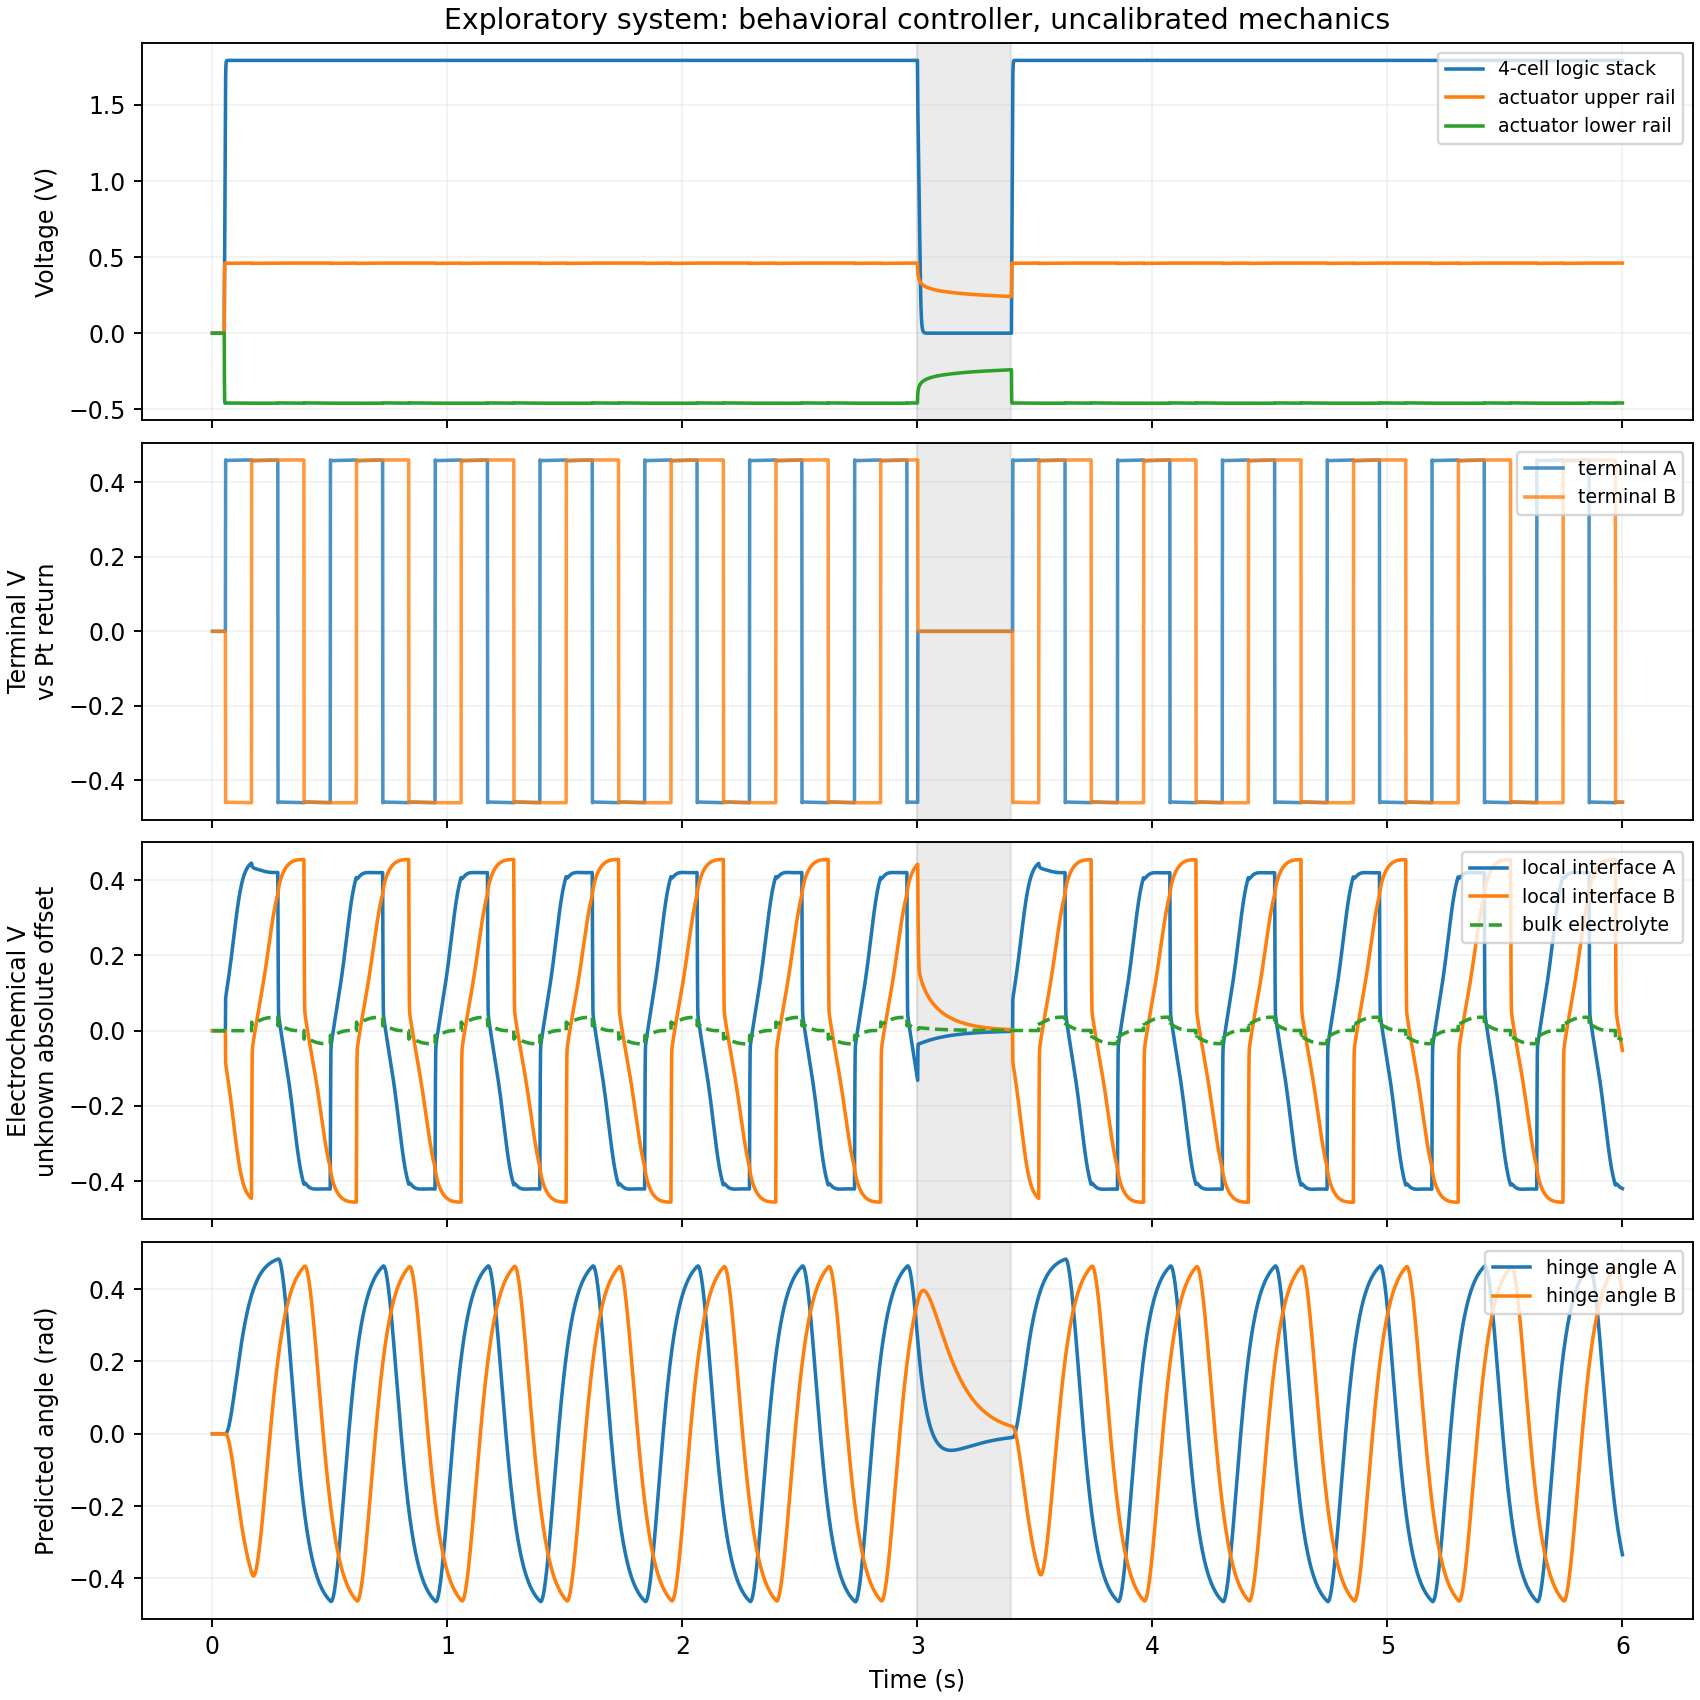

In [4]:
metrics = read("system_metrics.json")
print(json.dumps({key: metrics[key] for key in (
    "startup_enable_s", "enable_transitions", "mean_gait_Hz", "measured_phase_B_lag_cycles",
    "steady_logic_V", "steady_actuator_span_V", "bending_peak_to_peak_rad")}, indent=2))
display(Image(filename=str(OUTPUT / "system.png")))

## 5. Validation, sensitivity and energy

The runner checks terminal-current conservation, the absorbed-photon bound,
three meshes, a halved system timestep, a direct half-illumination DD point,
measured phase lag and startup/recovery. Photon-budget and dark-system/no-energy
limits are covered by tests. Table interpolation is bounded; voltages outside the
characterized range fail. Superposition at other wavelengths/temperatures is untested.

Bias, logic, drivers, electrolyte, Faradaic leakage, adsorption electrical work and
capacitor storage are reported separately. Interface $I\eta$ includes storage; it
must not be added again as dissipation. First-order time splitting introduces a
reported energy-balance residual. Mechanical work and efficiency are not calibrated.


{
  "medium_to_fine_Isc_relative_change": 0.0036560518952732934,
  "timestep_relative_changes": {
    "mean_gait_Hz": 2.220446049250313e-16,
    "bending_peak_to_peak_rad": 0.0005116870103309967,
    "bias_mean_W": 7.771561172376096e-16,
    "driver_J_per_cycle": 0.009536950628736607,
    "adsorption_J_per_cycle": 0.015662271976637943
  },
  "half_light_Isc_superposition_relative_error": 7.818438408468964e-06,
  "maximum_contact_current_imbalance": 3.0522070049260486e-12,
  "electrical_energy_balance_relative_residual": 0.0012708552022755038,
  "phase_B_lag_cycles": 0.25103229092027324,
  "published_responsivity_A_W_approximate": 0.3,
  "our_responsivity_A_W": 0.13549730611554417,
  "published_comparison_status": "conceptual DD uncalibrated; digitized S2 fit in separate published experiment",
  "layout_DRC_LVS_PEX": "not executed; no layout produced in milestone 1"
}
bias        : 8.96544 nW; 4.00000 nJ/cycle
logic       : 6.30533 nW; 2.81317 nJ/cycle
driver      : 0.80436 nW; 0.35887 

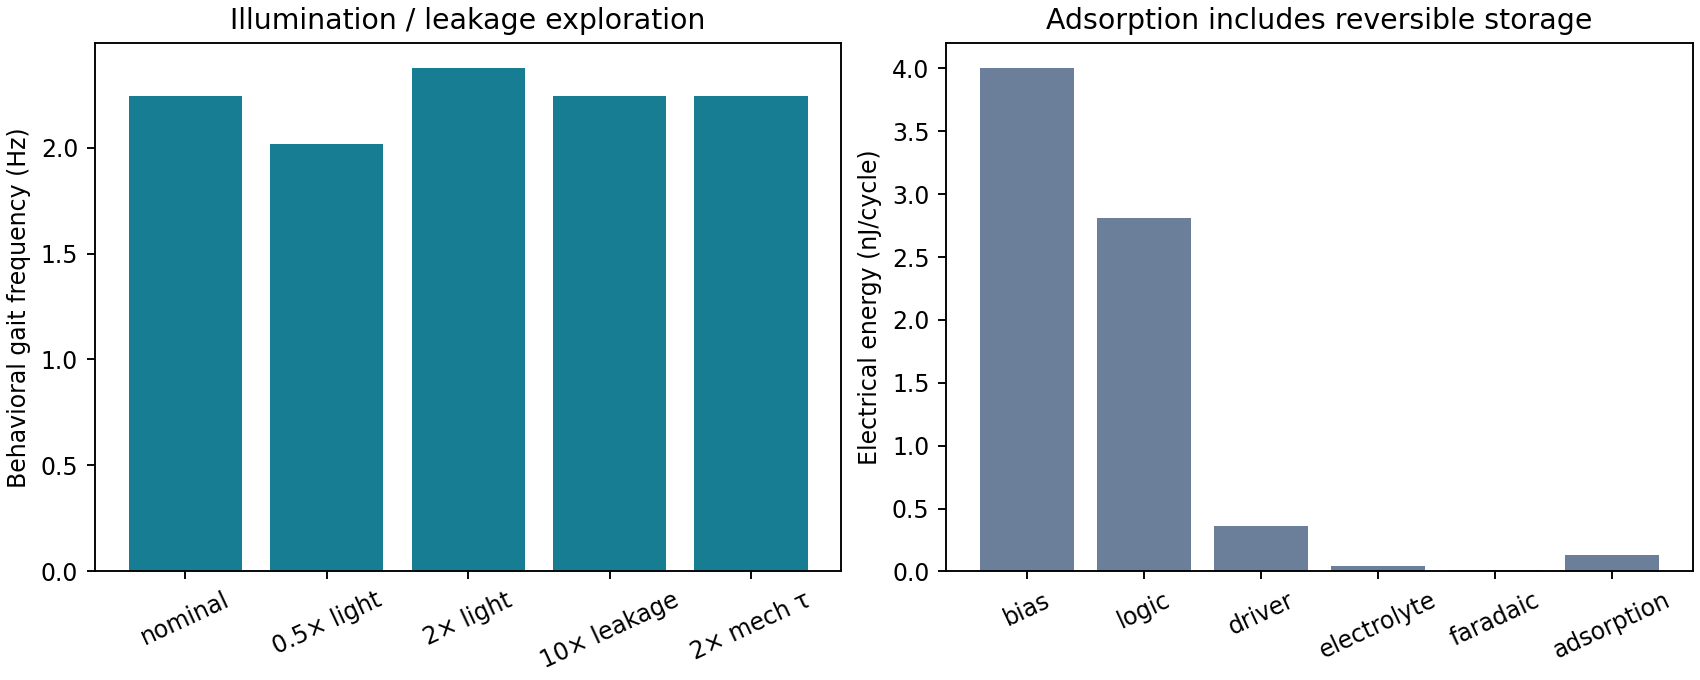

In [5]:
print(json.dumps(read("validation.json"), indent=2))
for part in ("bias", "logic", "driver", "electrolyte", "faradaic", "adsorption"):
    print(f"{part:12s}: {metrics[part+'_mean_W']*1e9:.5f} nW; "
          f"{metrics[part+'_J_per_cycle']*1e9:.5f} nJ/cycle")
display(Image(filename=str(OUTPUT / "sensitivity_energy.png")))

## 6. Initial foundry-model oscillator experiment: rejected on power

A three-stage RC-loaded SKY130 ring plus buffer uses foundry transistor models,
ideal timing passives and an external supply. An initial asymmetry and prescribed
power ramp seed startup; autonomous PV startup is not validated. This is our
candidate topology, not Reynolds' PTAT/relaxation design. The generated deck exposes
all W/L/R/C choices. The model file hash and installed PDK commit metadata are archived.

TT/SS/FF, supply and temperature runs are deterministic sensitivity checks;
they are not statistical mismatch or an exhaustive combined PVT matrix. A full-swing
oscillator can still fail the power budget. This candidate is rejected for the
proposed PV allocation. No controller layout should be derived from it as a final design.


TT 1.6 V 27 C: 23.538 kHz, 1.443 uW
SS 1.6 V 27 C: 20.950 kHz, 1.288 uW
FF 1.6 V 27 C: 25.720 kHz, 1.659 uW
TT 1.8 V 27 C: 27.783 kHz, 2.505 uW
TT 1.6 V 85 C: 26.293 kHz, 1.800 uW
{
  "nominal_ring_W": 1.443307297397861e-06,
  "logic_array_maximum_PV_W": 2.8902195180494104e-08,
  "ring_to_available_power_ratio": 49.9376358226222,
  "decision": "reject this ring for the proposed PV allocation; redesign reference/clock",
  "comparison": "ideal external 1.6 V SPICE supply vs conceptual TCAD array MPP",
  "not_tested": "PV-powered transistor startup, mismatch, layout or PEX"
}


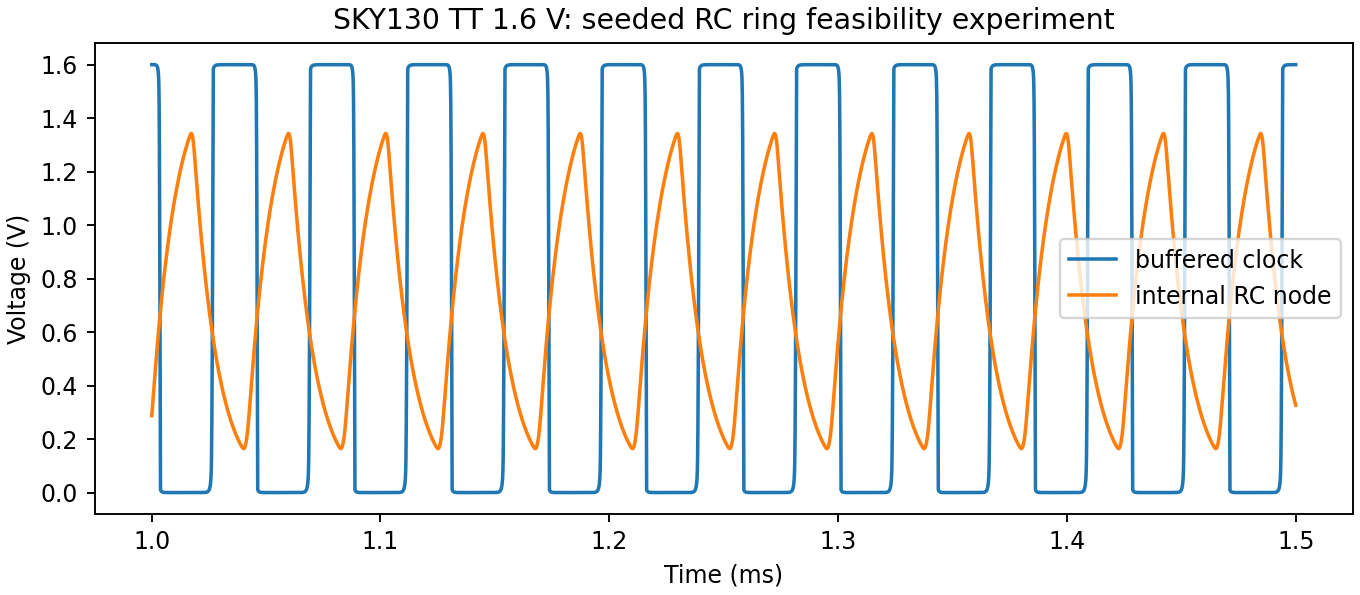

In [6]:
if RUN_SPICE:
    for r in read("spice_summary.json"):
        print(f"{r['corner'].upper()} {r['supply_V']} V {r['temperature_C']} C: "
              f"{r['frequency_Hz']/1e3:.3f} kHz, {r['mean_power_W']*1e6:.3f} uW")
    print(json.dumps(read("spice_budget.json"), indent=2))
    display(Image(filename=str(OUTPUT / "spice_ring.png")))
else:
    print("Not executed: install ngspice and a compatible SKY130A PDK to run this cell.")

## 7. Published PV extraction and reduced terminal fit

Figure S2E reports two series PVs, each 540 µm², under 660 nm light at
1000 W/m². The committed CSV retains pixel coordinates; the calibration stores
the source PDF checksum, axis positions, curve-color masks and explicit ±2-pixel
axis/±3-pixel trace sensitivity assumptions. Re-fitting needs no PDF or network.
To repeat image extraction, supply the original PDF to `examples.microrobot.digitize`.

The reusable `SingleDiodePV` fits
$I_{out}=I_{ph}(E/E_{ref})-I_0[\exp(V/(N_s n V_T))-1]$.
It has no series resistance, shunt leakage, junction charge or temperature
calibration. Measurement temperature is assumed 300 K. The small dark-trace
raster offset is retained in the residuals. Voltage uncertainty is propagated
through the local trace slope; correlated pixel samples are not independent
measurements. The 48 seeded perturbations give sensitivity ranges, not confidence
intervals. Effective $I_0,n,I_{ph}$ do not uniquely determine doping or lifetime.

The following command re-fits the CSV and reruns the coupled experiment. When
ngspice/SKY130 are available it also reruns all current clock characterization
decks, including finite-PV startup. Otherwise it uses explicitly archived clock
results and checks their circuit-source hash.


Clock characterization: rerun locally
{
  "fitted_terminal_model": {
    "saturation_A": 1.0585988034104368e-16,
    "ideality": 1.1447088539600483,
    "photocurrent_A": 1.4526236906638614e-07,
    "reference_irradiance_W_m2": 1000.0,
    "series_cells": 2,
    "temperature_K": 300
  },
  "fit_metrics": {
    "rms_current_error_A": 7.2206846547706585e-09,
    "maximum_current_error_A": 5.3833700547040904e-08,
    "weighted_rms_residual": 0.5989883803320543,
    "evaluations": 8,
    "points": 300,
    "ideality_at_bound": false
  },
  "pair_Voc_V": 1.245255703588111,
  "pair_MPP_V_A_W": [
    1.0707048175601896,
    1.3765322496075386e-07,
    1.473859711181757e-07
  ],
  "sensitivity": {
    "saturation_A": {
      "min": 1.7186433433162445e-17,
      "max": 6.690752062838831e-16
    },
    "ideality": {
      "min": 1.0613371976981587,
      "max": 1.2657730509384166
    },
    "photocurrent_A": {
      "min": 1.421738874614406e-07,
      "max": 1.4810940922670294e-07
    },
    "pa

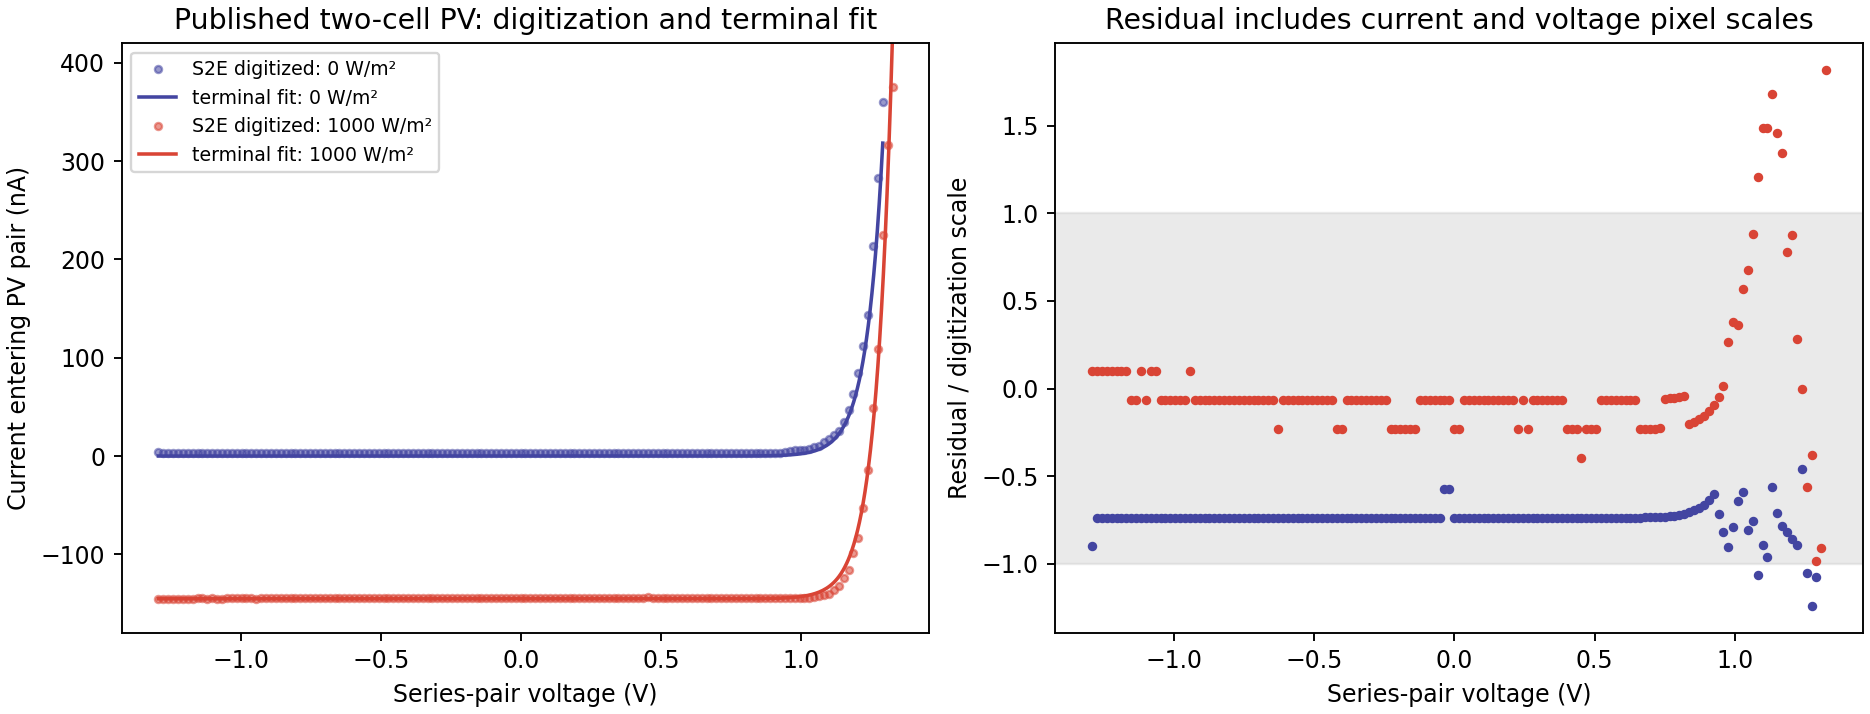

In [7]:
command = [sys.executable, "-m", "examples.microrobot.published"]
if RUN_SPICE:
    command.append("--spice")
with (OUTPUT / "notebook_published_run.log").open("w") as log:
    subprocess.run(command, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT, check=True)
fit = read("published/pv_fit.json")
report = read("published_system/report.json")
clock_summary = read("clock_final/summary.json")
print("Clock characterization:", "rerun locally" if RUN_SPICE else "archived results; source hash checked")
print(json.dumps({key: fit[key] for key in (
    "fitted_terminal_model", "fit_metrics", "pair_Voc_V", "pair_MPP_V_A_W", "sensitivity")}, indent=2))
display(Image(filename=str(OUTPUT / "published/pv_fit.png")))


## 8. PV-powered clock and actual digital-cell loading

Our new circuit uses a supply-dependent diode-stack bias, five current-starved
inverters, PDK MIM capacitors and two buffers. It is not the published compensated
PTAT/relaxation oscillator. A real SKY130 DFF and feedback inverter provide a
divide-by-two load. Their current is measured separately. Startup begins at the
zero-supply operating point and ramps illumination/supply; no UIC, seeded node
voltage or ideal startup pulse is used. Timing-capacitor asymmetry is intentional.

Three separately isolated cell proxies, each 150 µm², scale current density from
the measured large cells. This scaling and the chosen 2 pF supply capacitor are
design assumptions. Direct PV-powered SPICE is the electrical-startup reference.
The load includes the clock and first DFF, not the complete divider or drivers.

An oscillation pass checks sustained full-swing clock and correct first-DFF
division; the nominal PV maximum-power check is separate. Fixed-supply corner
loads can exceed available PV power. SF/FS finite-PV runs check loaded equilibria.
These deterministic process cases and separate temperature cases do not establish
statistical mismatch, passive corners or complete combined PVT coverage. The
frequency spread is substantial; compensation/trim remain future work.


TT,  26.9 C, 1.6000 V:   4.509 kHz,  11.791 nW; oscillation=True; PV-budget=True
TT,  26.9 C, 1.7000 V:   8.159 kHz,  26.164 nW; oscillation=True; PV-budget=True
TT,  26.9 C, 1.8000 V:  14.633 kHz,  55.250 nW; oscillation=True; PV-budget=True
TT,  26.9 C, 1.9000 V:  25.864 kHz, 110.941 nW; oscillation=True; PV-budget=False
TT,  26.9 C, 1.9400 V:  32.284 kHz, 142.170 nW; oscillation=True; PV-budget=False
SS,  26.9 C, 1.8000 V:   7.507 kHz,  29.603 nW; oscillation=True; PV-budget=True
FF,  26.9 C, 1.8000 V:  28.685 kHz, 108.501 nW; oscillation=True; PV-budget=False
SF,  26.9 C, 1.8000 V:  42.488 kHz, 115.023 nW; oscillation=True; PV-budget=False
FS,  26.9 C, 1.8000 V:   5.122 kHz,  35.651 nW; oscillation=True; PV-budget=True
TT,   0.0 C, 1.8000 V:   8.571 kHz,  32.702 nW; oscillation=True; PV-budget=True
TT,  85.0 C, 1.8000 V:  34.799 kHz, 131.306 nW; oscillation=True; PV-budget=False
TT,  26.9 C, 1.8000 V:  14.633 kHz,  55.758 nW; oscillation=True; PV-budget=True
TT,  26.9 C, 1.7715 V: 

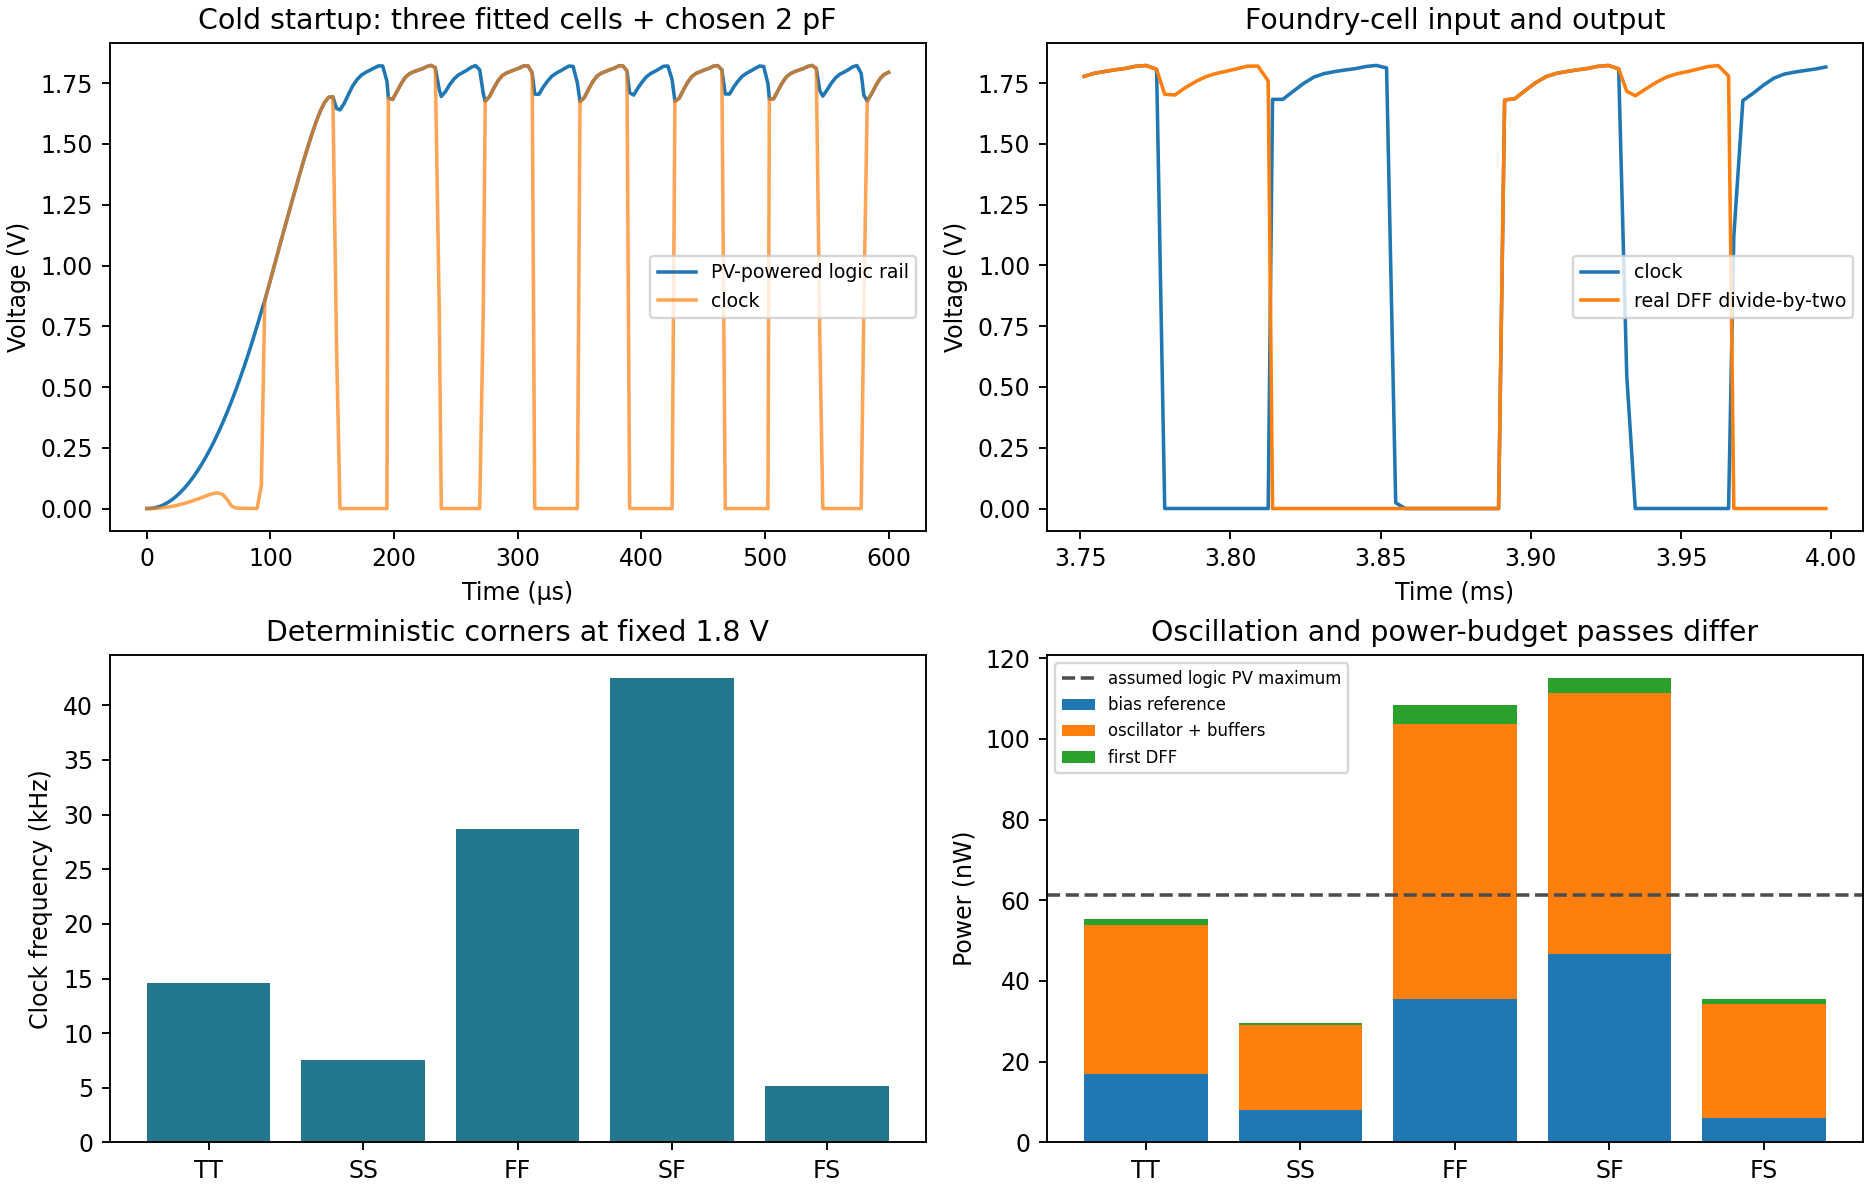

In [8]:
for r in clock_summary["cases"]:
    print(f"{r['corner'].upper():2s}, {r['temperature_C']:5.1f} C, "
          f"{r['steady_supply_V']:.4f} V: {r['frequency_Hz']/1e3:7.3f} kHz, "
          f"{r['mean_power_W']*1e9:7.3f} nW; oscillation={r['passed']}; "
          f"PV-budget={r['within_nominal_PV_maximum_power']}")
print("Clock timestep relative changes:", clock_summary["timestep_relative_changes"])
display(Image(filename=str(OUTPUT / "published_system/clock_validation.png")))


## 9. Updated system, power accounting and verified phase RTL

Bounded TT voltage/frequency/current lookups couple the clock to the fitted PV
terminal model. A withheld 1.75 V SPICE point checks interpolation. The quasistatic
proxy omits supply ripple: its direct PV-SPICE discrepancy is reported, including
about 7% power error. Subthreshold startup load is an approximation; use direct
SPICE for electrical startup. The remaining divider has an explicitly assumed
20 fF effective switched capacitance and leakage in addition to the measured
first DFF. The two phase outputs use /8192 and a quarter-period lag.

Reference, oscillator/buffers, first DFF, remaining-logic estimate, behavioral
driver, electrolyte, Faradaic and adsorption energies are separate. Mechanical
work is uncalibrated. Supply cutoff/recovery, illumination, digitization extremes
and timestep checks do not validate walking speed or a complete transistor controller.

The parameterized RTL implements the divider/phases. Icarus checks duty, period,
phase lag and asynchronous reset/restart; Yosys performs generic synthesis.
Neither a physical reset detector nor PDK mapping, timing signoff or layout is
implemented. The first DFF's SPICE loading does not establish whole-divider power.


{
  "validation": {
    "clock_interpolation_withheld_1v75": {
      "frequency_relative": 0.0013667988135025455,
      "analog_current_relative": 0.009687825128413818
    },
    "direct_PV_SPICE_comparison": {
      "supply_voltage_relative_error": 0.002562867778584721,
      "frequency_relative_error": -0.02064275849754449,
      "power_relative_error": 0.07031764091714288,
      "scope": "Quasi-static clock+first-FF proxy vs direct PV-powered SPICE; supply ripple absent in proxy"
    },
    "timestep_relative_changes": {
      "mean_gait_Hz": 1.1102230246251565e-16,
      "bending_peak_to_peak_rad": 3.3701117109430356e-05,
      "bias_mean_W": 2.220446049250313e-16,
      "driver_J_per_cycle": 0.01415602649085046
    },
    "active_logic_voltage_min_V": 1.7644498341531143,
    "active_logic_voltage_max_V": 1.7740591867607174,
    "phase_B_lag_cycles": 0.24942737277819524,
    "electrical_energy_balance_relative_residual": 0.00031790759111666937,
    "scope": "Fitted terminal PV, cha

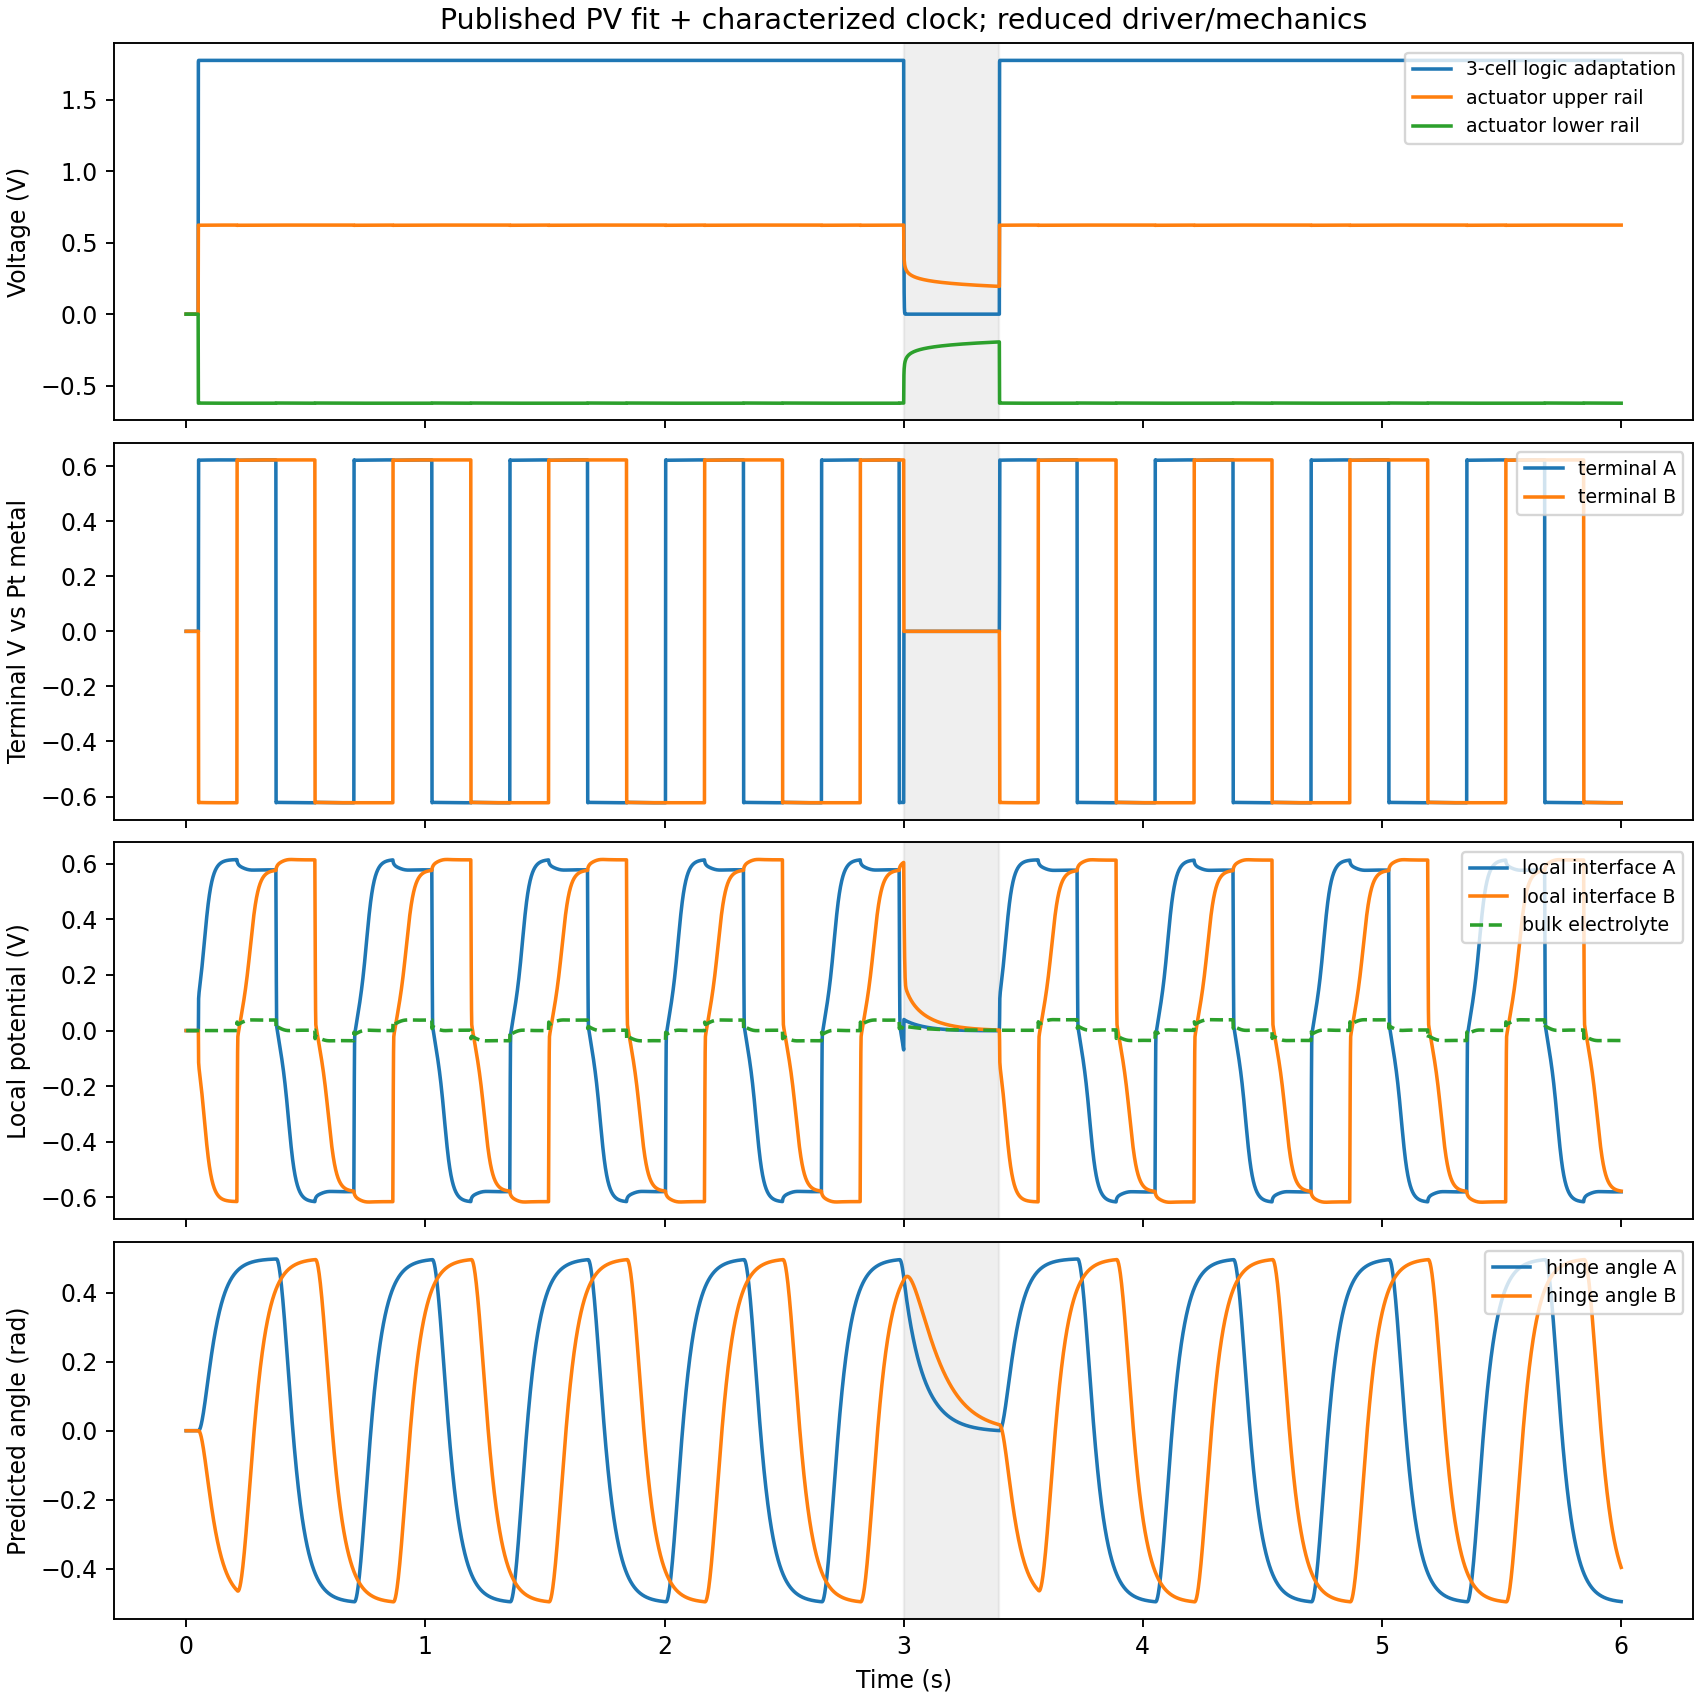

/Users/abhineet/Documents/opentcad_final/examples/microrobot/rtl/phase_generator_tb.v:29: $finish called at 981000 (1ps)
Generic synthesis: 50 cells; 13 flops (not PDK mapped)


In [9]:
print(json.dumps({key: report[key] for key in ("validation", "energy", "provenance")}, indent=2))
print("Updated gait frequency:", report["metrics"]["mean_gait_Hz"], "Hz")
display(Image(filename=str(OUTPUT / "published_system/system.png")))

rtl = ROOT / "examples/microrobot/rtl"
rtl_output = OUTPUT / "rtl"
rtl_output.mkdir(exist_ok=True)
if shutil.which("iverilog") and shutil.which("vvp"):
    import tempfile
    with tempfile.TemporaryDirectory(prefix="opentcad-rtl-") as temporary:
        executable = Path(temporary) / "phase"
        subprocess.run(["iverilog", "-g2012", "-s", "phase_generator_tb", "-o", str(executable),
                        str(rtl / "phase_generator.v"), str(rtl / "phase_generator_tb.v")], check=True)
        simulation = subprocess.run(["vvp", str(executable)], capture_output=True, text=True, check=True)
    (rtl_output / "simulation.log").write_text(simulation.stdout + simulation.stderr)
    assert "PASS" in simulation.stdout
    print(simulation.stdout.splitlines()[-1])
else:
    print("Icarus not installed; RTL simulation not rerun.")
if shutil.which("yosys"):
    script = ("read_verilog examples/microrobot/rtl/phase_generator.v; "
              "synth -top phase_generator; stat; "
              "write_json examples/microrobot/results/rtl/generic_netlist.json")
    synthesis = subprocess.run(["yosys", "-p", script], cwd=ROOT, capture_output=True, text=True, check=True)
    (rtl_output / "synthesis.log").write_text(synthesis.stdout + synthesis.stderr)
    cells = read("rtl/generic_netlist.json")["modules"]["phase_generator"]["cells"]
    print("Generic synthesis:", len(cells), "cells;",
          sum("DFF" in cell["type"] for cell in cells.values()), "flops (not PDK mapped)")
else:
    print("Yosys not installed; generic synthesis not rerun.")


## 10. Next gates through physical layout

1. Validate transistor-level actuator drivers, gate level shifting and an actual
   reset/brownout detector, using the shared VSS/actuator-midpoint topology.
   Evaluate full-divider loading, leakage, illumination, startup and corners.
   Resolve overvoltage, frequency trim and storage/footprint constraints.
2. Lay out the validated bias/clock, timing components and drivers with justified
   matching, symmetry, contacts, guard rings and sensitive routing. Implement a
   small digital macro; use OpenLane if size warrants it.
3. Assemble defined supply/output/test pins, run PDK-supported DRC and Netgen LVS,
   extract parasitics, repeat electrical simulations and iterate. Netgen is not
   installed in the currently audited environment.

**Executed here:** conceptual device/system experiments, published-curve fitting,
clock/PV startup/corner simulations when tools are present, phase RTL and generic
synthesis when tools are present. **Pending:** calibrated TCAD/actuator mechanics,
complete transistor schematic, analog/digital layout, DRC/LVS, extraction and
pre/post-layout comparison. The full regression suite passed 170 tests on
2026-10-27, with one existing Auger diagnostic warning. Conceptual PVs and
postprocessed actuators remain separate from PDK controller layout.

Our contributions are reusable optical/current support, the charge-conservation
correction, terminal fitting/MPP/SPICE export, numerical regressions, attributed
PV extraction and this functional clock/system/RTL implementation. Original
microrobot concepts belong to the cited authors. Open tools/PDK retain their
licenses; application code follows the repository's Apache-2.0 license.

The [official Code-a-Chip rules](https://sscs.ieee.org/membership/awards/ieee-sscs-code-a-chip-travel-grant-awards/)
were checked on 2026-10-26: deadline October 31, 2026 at 11:59 AM Pacific
(November 1, 00:29 IST). The format is an openly licensed reproducible notebook
in the official repository's project directory. Layout is encouraged, not
required. No submission, publication or push has been performed.


## Subsequent physical/electrical milestone

The driver and bias-layout work is in [electrical_layout.ipynb](electrical_layout.ipynb) and [PHYSICAL_VALIDATION.md](PHYSICAL_VALIDATION.md). This notebook retains the earlier executed model assumptions and results; they have not been replaced by the separate transistor/post-layout experiments.